<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/industry-allocation/01_data_and_covariance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 - 30 US industries, 1926-2018: data and covariance estimation

Monthly value-weighted returns of 30 industry portfolios (Kenneth R. French Data Library). Allocations in 02 need a covariance matrix from 60 months of data for 30 assets: 465 parameters from 1,800 numbers, so estimation error matters.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/industry-allocation
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from alloc import *
plt.style.use("quant.mplstyle")

R = load_french("data/ind30_m_vw_rets.csv") / 100           # 30 value-weighted US industry portfolios
ff = load_french("data/F-F_Research_Data_Factors_m.csv") / 100  # Mkt-RF, SMB, HML, RF
cap = load_french("data/ind30_m_size.csv") * load_french("data/ind30_m_nfirms.csv")   # industry market cap
n = R.shape[1]
print(R.shape, R.index[0], "->", R.index[-1])

(1110, 30) 1926-07 -> 2018-12


In [3]:
vol = R.std() * np.sqrt(12)
print("annual vol: min", round(vol.min(), 3), vol.idxmin(), " max", round(vol.max(), 3), vol.idxmax(), " median", round(vol.median(), 3))
C = R.corr().values
print("average pairwise correlation:", round((C.sum() - n) / (n * (n - 1)), 2))
# vols from 16% (telecoms) to 37% (coal), median 24%: much less spread than across asset classes
# average correlation 0.65: industries are all exposed to the same market

annual vol: min 0.159 Telcm  max 0.374 Coal  median 0.237
average pairwise correlation: 0.65


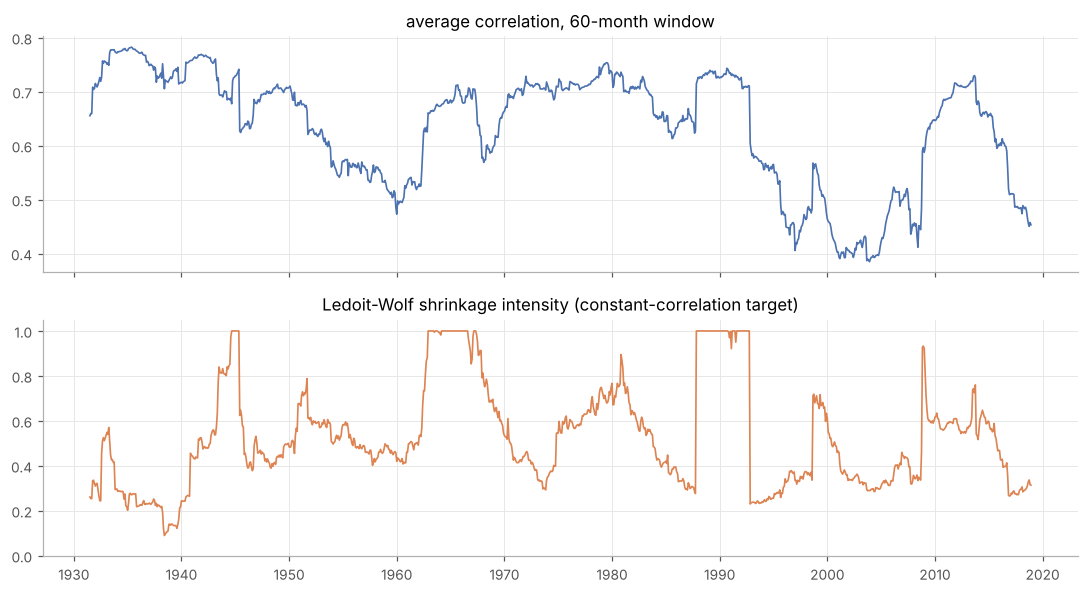

shrinkage: mean 0.53  min 0.09  max 1.0


In [4]:
roll_corr = pd.Series([(R.iloc[t - 60:t].corr().values.sum() - n) / (n * (n - 1)) for t in range(60, len(R))], index=R.index[60:])
shrink = pd.Series([ledoit_wolf_cc(R.values[t - 60:t])[1] for t in range(60, len(R))], index=R.index[60:])
fig, ax = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax[0].plot(roll_corr.index.to_timestamp(), roll_corr.values); ax[0].set_title("average correlation, 60-month window")
ax[1].plot(shrink.index.to_timestamp(), shrink.values, color="C1"); ax[1].set_title("Ledoit-Wolf shrinkage intensity (constant-correlation target)")
ax[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()
print("shrinkage: mean", round(shrink.mean(), 2), " min", round(shrink.min(), 2), " max", round(shrink.max(), 2))
# when correlations are high and similar (crises) the constant-correlation target is close to the truth -> high shrinkage
# when industries split into groups the target is wrong and the estimator trusts the sample more
# tests in test_alloc.py check both cases on simulated data